<a href="https://colab.research.google.com/github/3b232076/2026_DL_hws/blob/main/hw4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HW4-2 四資四乙 3B232076-陳韻如

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual

## 顯示中文

In [ ]:
# 下載思源黑體字型（支援中文）
!wget -qO /usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf

# 重新載入字型
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/NotoSansCJKtc-Regular.otf')
plt.rcParams['font.family'] = 'Noto Sans CJK TC'

## 一、資料預處理

In [ ]:
# 下載 CIFAR-10 數據集
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [ ]:
# 顯示資料形狀
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


## 資料常模化(normalization)

In [ ]:
x_train = x_train / 255
x_test = x_test / 255

## One-hot encoding

In [ ]:
y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)

## 顯示三張訓練圖片與真實標籤

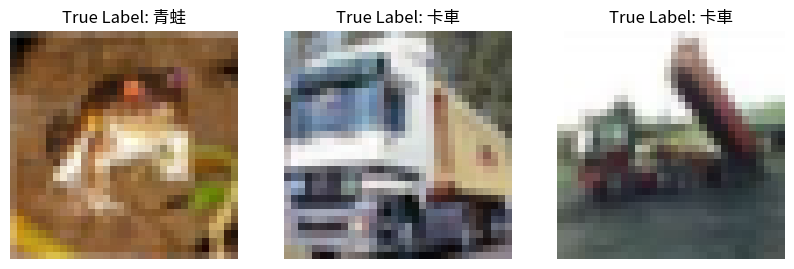

In [ ]:
class_name = ['飛機', '汽車', '鳥', '貓', '鹿', '狗', '青蛙', '馬', '船', '卡車']

plt.figure(figsize=(10,4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_train[i])
    plt.title(f"True Label: {class_name[y_train[i].item()]}")
    plt.axis('off')
plt.show()

## 二、建立神經網路模型

In [ ]:
model = Sequential()

### 第一層：卷積層 (32 個 Filter，大小為 5x5)
* 圖片尺寸為 32x32
* 彩色圖片 3 通道（RGB）
* (32, 32, 32)
* 卷積層參數 = (Filter高 × Filter寬 × 前層輸入通道數 + 偏值) × 本層通道數

In [ ]:
model.add(Conv2D(32, (5,5), padding='same',
        input_shape=(32,32,3),
        activation='relu'))  # (5x5x3+1)x32 = 2432

### 第二層：Dropout 0.25

In [ ]:
model.add(Dropout(0.25))

### 第三層：池化層
* (32, 32, 32) → (16, 16, 32)
* 保留前一層32 個通道

In [ ]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第四層：卷積層 (64 個 Filter，大小為 3x3)
* 圖片尺寸為 16x16
* (16, 16, 64)
* 前一層輸出32 個通道
* 本層64 通道

In [ ]:
model.add(Conv2D(64, (3,3), padding='same',
        activation='relu',))  # (3x3x32+1)x64 = 18496

### 第五層：Dropout 0.25

In [ ]:
model.add(Dropout(0.25))

### 第六層：池化層
* (16, 16, 64) → (8, 8, 64)
* 保留前一層64 個通道

In [ ]:
model.add(MaxPooling2D(pool_size=(2,2)))

### 第七層：拉平層
* (8, 8, 64) → 4096

In [ ]:
model.add(Flatten())

### 第八層：Dropout 0.25

In [ ]:
model.add(Dropout(0.25))

### 第九層：全連接層，1024 個神經元
* 1024 個神經元對應CIFAR-10 的10 類別
* 每個神經元連接前一層的4096 個輸入，共有4194304 個權重+ 1024 個偏值= 4195328 個參數。

In [ ]:
model.add(Dense(1024, activation='relu')) # 4096x1024+1024 = 4195328

### 第十層：Dropout 0.25

In [ ]:
model.add(Dropout(0.25))

### 第十一層：全連接層，10 個神經元

In [ ]:
model.add(Dense(10, activation='softmax')) # 1024x10+10 = 10250

In [ ]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)

### 批次訓練 Input Shape 與各層 Output Shape

批次大小（batch_size）設定為 128，每次輸入 128 張 32×32 的 RGB 圖片。

Input Shape：(128, 32, 32, 3)

各層 Output Shape：
1. Conv2D：(128, 32, 32, 32)
2. Dropout：(128, 32, 32, 32)
3. MaxPooling2D：(128, 16, 16, 32)
4. Conv2D：(128, 16, 16, 64)
5. Dropout：(128, 16, 16, 64)
6. MaxPooling2D：(128, 8, 8, 64)
7. Flatten：(128, 4096)
8. Dropout：(128, 4096)
9. Dense：(128, 1024)
10. Dropout：(128, 1024)
11. Dense：(128, 10)

以上為完整批次的形狀，最後一個批次可能不足 128 筆。

## 三、訓練神經網路模型

In [ ]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy'])

In [ ]:
train_history = model.fit(
    x_train, y_train_oh,
    validation_split=0.2,
    batch_size=128,
    epochs=20,
    verbose=2)

Epoch 1/20
313/313 - 150s - 479ms/step - accuracy: 0.8134 - loss: 0.5284 - val_accuracy: 0.7321 - val_loss: 0.7988
Epoch 2/20
313/313 - 196s - 625ms/step - accuracy: 0.8412 - loss: 0.4570 - val_accuracy: 0.7373 - val_loss: 0.7696
Epoch 3/20
313/313 - 149s - 474ms/step - accuracy: 0.8521 - loss: 0.4166 - val_accuracy: 0.7376 - val_loss: 0.7703
Epoch 4/20
313/313 - 145s - 463ms/step - accuracy: 0.8742 - loss: 0.3601 - val_accuracy: 0.7362 - val_loss: 0.7716
Epoch 5/20
313/313 - 148s - 474ms/step - accuracy: 0.8865 - loss: 0.3235 - val_accuracy: 0.7376 - val_loss: 0.7725
Epoch 6/20
313/313 - 198s - 633ms/step - accuracy: 0.8942 - loss: 0.2954 - val_accuracy: 0.7404 - val_loss: 0.7835
Epoch 7/20
313/313 - 143s - 457ms/step - accuracy: 0.9107 - loss: 0.2544 - val_accuracy: 0.7367 - val_loss: 0.7927
Epoch 8/20
313/313 - 147s - 469ms/step - accuracy: 0.9223 - loss: 0.2253 - val_accuracy: 0.7397 - val_loss: 0.8160
Epoch 9/20
313/313 - 204s - 650ms/step - accuracy: 0.9237 - loss: 0.2186 - val_a

## 四、顯示 loss & accuracy 折線圖

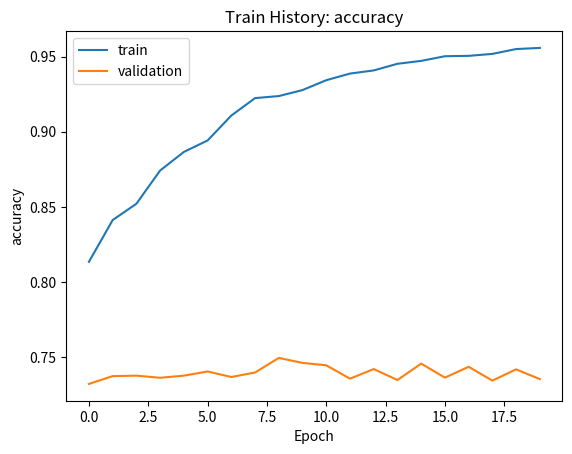

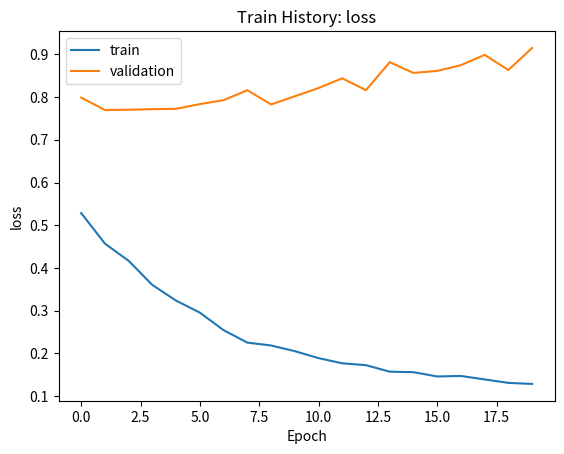

In [ ]:
def show_train_history(train_history, train, validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title(f'Train History: {train}')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train', 'validation'], loc='upper left')
  plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy')
show_train_history(train_history, 'loss', 'val_loss')

### Overfitting 分析

從訓練結果可以觀察到，隨著 Epoch 增加，訓練 Accuracy 持續上升，Loss 逐漸下降。

第 20 個 Epoch 的訓練 Accuracy 為 95.57%，驗證 Accuracy 為 73.53%，兩者相差 22.04 個百分點。

此外，訓練 Loss 為 0.1286，驗證 Loss 為 0.9150，顯示模型出現過度擬合（Overfitting）的現象。

雖然模型加入 Dropout 0.25，但仍無法完全避免過度擬合。

## 五、評估模型準確率

In [ ]:
scores = model.evaluate(x_test, y_test_oh)
print(f"accuracy: {scores[1]*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.7287 - loss: 0.9407
accuracy: 72.87%


## 六、預測

In [ ]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step


In [ ]:
predictions.shape

(10000, 10)

In [ ]:
predictions

array([[5.6401396e-04, 3.6899393e-05, 1.4448054e-03, ..., 6.5276654e-05,
        4.5554158e-03, 4.2923351e-04],
       [2.8697839e-03, 7.0659220e-01, 1.0817345e-07, ..., 5.4869718e-09,
        2.9027095e-01, 2.6657089e-04],
       [1.8567204e-01, 2.0314352e-01, 1.8432272e-04, ..., 1.2626497e-04,
        5.8479714e-01, 2.3403402e-02],
       ...,
       [8.1880593e-08, 6.5548084e-10, 3.4919135e-02, ..., 1.1647267e-04,
        2.5312963e-06, 1.2118946e-08],
       [1.2939736e-02, 2.8788915e-01, 1.7890246e-03, ..., 1.7692437e-04,
        1.2041340e-06, 2.8226068e-04],
       [1.9162973e-08, 1.1205456e-08, 8.5595201e-07, ..., 9.9599564e-01,
        4.1605515e-09, 1.4981151e-08]], shape=(10000, 10), dtype=float32)

In [ ]:
predicted_classes = np.argmax(predictions, axis=1)

## 七、顯示圖片與標籤名稱

In [ ]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, true_labels, pred_labels, label_names, idx, num):
  plt.figure(figsize=(6, 7))
  if num > 25: num = 25
  for i in range(num):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[idx + i])

    true_idx = np.squeeze(true_labels[idx + i])
    pred_idx = np.squeeze(pred_labels[idx + i])

    true_name = label_names[true_idx]
    pred_name = label_names[pred_idx]

    plt.title(f'True: {true_name}\nPred: {pred_name}', fontsize=10)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

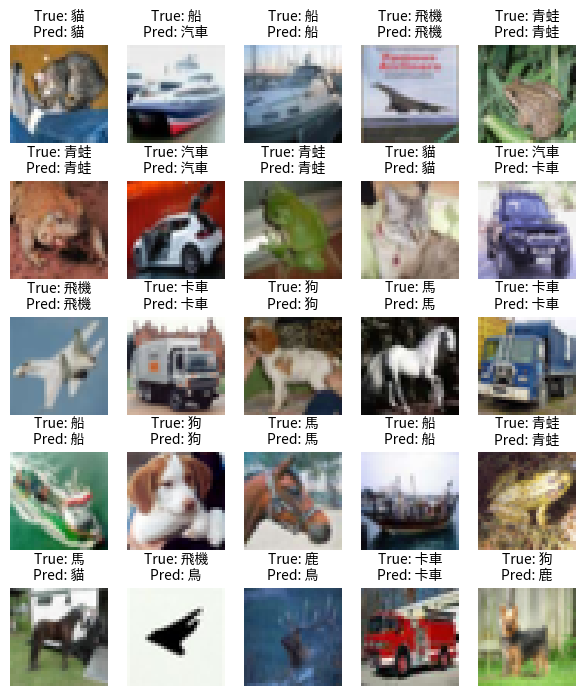

In [ ]:
plot_images_labels_prediction(x_test, y_test, predicted_classes, class_name, idx=0, num=25)

## 八、混淆矩陣 (Confusion Matrix)

In [ ]:
import pandas as pd

pd.crosstab(np.squeeze(y_test), predicted_classes, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,813,16,39,12,21,4,17,6,49,23
1,24,821,4,6,8,5,16,3,16,97
2,70,1,630,41,103,37,82,14,15,7
3,22,8,97,485,78,138,115,26,13,18
4,14,2,69,37,758,15,53,41,10,1
5,9,2,66,147,81,584,58,41,6,6
6,8,3,35,38,35,4,868,2,3,4
7,19,4,26,27,100,57,19,731,4,13
8,75,29,14,11,14,11,15,3,798,30


## 九、儲存完整模型

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/

/content/drive/MyDrive/Colab Notebooks


In [ ]:
model.save('cnn_cifar10_model_4-2.keras')

## 十、interact_manual

In [ ]:
def test(測試編號):
  plt.imshow(x_test[測試編號], cmap='Greys')
  print('神經網路判斷為：', class_name[predicted_classes[測試編號]])
  print('正確答案為：', class_name[np.squeeze(y_test[測試編號])])

interact_manual(test, 測試編號=(0, len(x_test)-1))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>

### 比較結果分析

hw4-1使用較簡單的八層 CNN 架構，而 hw4-2 增加卷積層的 Filter 數量，並加入四層 Dropout 0.25，同時將全連接層增加至 1024 個神經元。

從測試結果可以發現，hw4-1 的準確率，為 70.97%，hw4-2 則提升至 72.87%，增加了 1.9 個百分點。

雖然 hw4-2 的測試準確率較高，但模型參數數量也大幅增加，而且訓練與驗證準確率存在明顯差距，顯示仍有 Overfitting 的問題。

整體而言，hw4-2 在測試準確率方面，優於 hw4-1，但模型複雜度也較高。